# 📈 Projet d'Économétrie : Modélisation du Market Price
**Master IREF**

---

* **Vianney Mathon**
* **Jules Marin**
* **Dorian Fernandez**

---

<br><br><br>

# 1. Exploration et Nettoyage des Données  
* Importation des données
* Statistiques descriptives
* Nombre de valeurs manquantes
* Distribution de la variable cible market_price

--- DIMENSIONS DU DATASET ---
Nombre d'observations : 25000
Nombre de variables : 31
----------------------------------------

--- STATISTIQUES DESCRIPTIVES ---


,inflation,interest_rate,gdp_growth,unemployment,volatility_index,revenue,debt,assets,equity,cash_flow,...,momentum_3m,momentum_6m,momentum_12m,volume,liquidity_ratio,bid_ask_spread,var_95,expected_shortfall,credit_spread,market_price
count,22954.000000,22942.000000,23024.000000,23003.000000,22986.000000,22992.000000,23049.000000,22983.000000,23040.000000,23026.000000,...,23045.000000,23088.000000,22986.000000,2.295700e+04,23001.000000,22986.000000,22989.000000,23024.000000,22980.000000,23019.000000
mean,1.998373,3.003064,2.504490,5.999400,20.006812,26447.062859,3802.096750,41080.931715,37360.883430,5992.071113,...,0.049755,0.079672,0.117871,2.238085e+05,1.497681,0.020012,-0.049976,-0.070221,1.400770,0.435952
std,0.499422,1.003234,0.998813,1.502547,5.000279,17271.423932,3000.838330,21814.073732,22171.157492,2509.027883,...,0.100352,0.150334,0.198952,2.133506e+05,0.400813,0.005997,0.020112,0.029915,0.397753,0.122310
min,0.038800,-1.465604,-1.657734,-0.694453,0.003339,2260.220234,226.619440,4076.436996,-18947.863061,-5034.714916,...,-0.366429,-0.494657,-0.845887,8.375595e+03,-0.190893,-0.002893,-0.121870,-0.193651,-0.206283,0.137146
25%,1.661496,2.321947,1.826057,5.000692,16.642896,14704.191088,1868.055637,25850.924810,21957.592041,4292.551199,...,-0.017791,-0.022667,-0.016230,9.406408e+04,1.227508,0.015972,-0.063583,-0.090408,1.131616,0.348725
50%,1.999367,3.006079,2.509756,6.001142,20.022101,22047.270464,2971.730035,36251.427492,32712.741417,5991.295839,...,0.050345,0.077865,0.118909,1.618182e+05,1.498745,0.019992,-0.049878,-0.070303,1.402078,0.419482
75%,2.336108,3.685908,3.179248,7.008648,23.344389,33299.644534,4745.504414,50911.257840,47472.157860,7691.363810,...,0.118069,0.181736,0.252120,2.784206e+05,1.766869,0.024066,-0.036365,-0.049992,1.670631,0.504885
max,3.971166,6.727833,6.260155,11.744673,41.010129,340193.153620,48233.434983,240648.808729,237020.953923,15659.764968,...,0.480185,0.658906,0.903163,4.055300e+06,3.140408,0.044920,0.024553,0.068338,3.026309,1.551783



--- VALEURS MANQUANTES ---
interest_rate         2058
sector                2052
inflation             2046
volume                2043
audit_quality         2040
market_beta           2033
region                2025
roa                   2024
credit_spread         2020
assets                2017
volatility_index      2014
bid_ask_spread        2014
momentum_12m          2014
roe                   2011
var_95                2011
revenue               2008
rating_category       2004
liquidity_ratio       1999
unemployment          1997
eps                   1989
market_price          1981
expected_shortfall    1976
gdp_growth            1976
cash_flow             1974
dividend_yield        1964
equity                1960
momentum_3m           1955
debt                  1951
listing_market        1923
pe_ratio              1918
momentum_6m           1912
dtype: int64


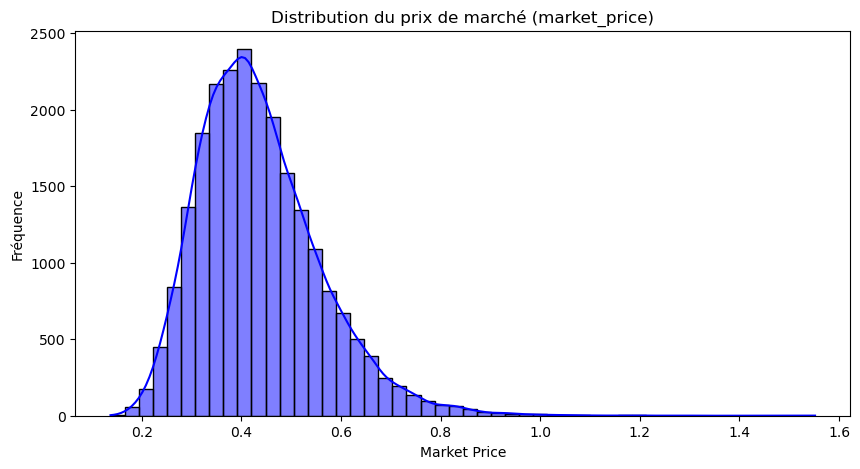

In [78]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1.1 Chargement du dataset
df = pd.read_csv('data/finance_dataset_25000_with_qualitative.csv')

# Affichage des principales caractéristiques
print("--- DIMENSIONS DU DATASET ---")
print(f"Nombre d'observations : {df.shape[0]}")
print(f"Nombre de variables : {df.shape[1]}")
print("-" * 40)

df.head()

# 1.2 Statistiques descriptives
print("\n--- STATISTIQUES DESCRIPTIVES ---")
display(df.describe()) # display() fait un joli tableau dans Jupyter

# 1.3 Analyse des valeurs manquantes
print("\n--- VALEURS MANQUANTES ---")
valeurs_manquantes = df.isnull().sum()
print(valeurs_manquantes[valeurs_manquantes > 0].sort_values(ascending=False))

# 1.4 Distribution de la variable dépendante (market_price)
plt.figure(figsize=(10, 5))
sns.histplot(df['market_price'], kde=True, bins=50, color='blue')
plt.title('Distribution du prix de marché (market_price)')
plt.xlabel('Market Price')
plt.ylabel('Fréquence')
plt.show()

On observe une distribution de type gaussienne avec une asymétrie à droite.

## 1.1. Gestion des NA de "Caractéristiques des entreprises"
* Suppression des observations sans variable cible (market_price NA)

In [79]:
# 1. Suppression des lignes où market_price est manquant
df = df.dropna(subset=['market_price'])

# 2. Calcul du bilan des NA pour toutes les colonnes
na_counts = df.isnull().sum()
na_percentages = (df.isnull().sum() / len(df)) * 100

# 3. Création d'un tableau récapitulatif
bilan_na = pd.DataFrame({
    'NA Absolus': na_counts,
    'Pourcentage (%)': na_percentages.round(2)
})

# 4. Affichage (on trie par importance pour voir ce qu'il reste à traiter)
print(f"Dimensions après suppression des market_price manquants : {df.shape}")
print("\n--- ÉTAT DES VALEURS MANQUANTES PAR COLONNE ---")
print(bilan_na[bilan_na['NA Absolus'] > 0].sort_values(by='NA Absolus', ascending=False))

Dimensions après suppression des market_price manquants : (23019, 31)

--- ÉTAT DES VALEURS MANQUANTES PAR COLONNE ---
                    NA Absolus  Pourcentage (%)
interest_rate             1898             8.25
sector                    1896             8.24
inflation                 1885             8.19
roa                       1870             8.12
audit_quality             1868             8.12
volume                    1866             8.11
assets                    1859             8.08
region                    1858             8.07
volatility_index          1853             8.05
bid_ask_spread            1853             8.05
market_beta               1852             8.05
credit_spread             1851             8.04
momentum_12m              1851             8.04
revenue                   1849             8.03
unemployment              1848             8.03
var_95                    1848             8.03
roe                       1845             8.02
liquidity_ratio  

### Analyse de Cohérence du Bilan (Assets, Equity, Debt)

Avant d'imputer les données, nous analysons la structure des valeurs manquantes sur les trois piliers du bilan comptable. L'objectif est de vérifier si l'identité fondamentale **$Assets = Equity + Debt$** peut être utilisée pour reconstituer les informations manquantes.

**Logique de l'analyse :**
1. **Identification des combinaisons :** Nous isolons les lignes où au moins une donnée manque pour observer si les NA sont isolés (calcul possible) ou groupés (calcul impossible).
2. **Calcul des moyennes :** L'ajout de la ligne `Moyenne` en fin de tableau permet de comparer le poids financier des entreprises concernées par les NA avec la tendance globale du dataset.

**Décision :** Si une seule variable manque sur les trois, nous la déduisons mathématiquement, garantissant une précision de 100% sans biais statistique.

In [80]:
# asset = equity + debt

# 1. On isole les 3 colonnes comptables
cols_comptables = ['assets', 'debt', 'equity']

# 2. On crée un tableau de booléens (True si NA, False si valeur présente)
mask_na = df[cols_comptables].isnull()

# 3. On filtre pour ne garder que les lignes où au moins UNE des trois variables est manquante
lignes_avec_na = mask_na[mask_na.any(axis=1)]

# 4. On compte la fréquence de chaque combinaison
analyse_na_comptables = lignes_avec_na.value_counts().reset_index(name='Nombre de lignes')

print("--- ANALYSE DES VALEURS MANQUANTES : ASSETS, DEBT, EQUITY ---")
print("Lecture : True = Valeur Manquante, False = Valeur Présente\n")
analyse_complete = pd.concat([analyse_na_comptables, pd.DataFrame([df[cols_comptables].mean()], index=['Moyenne'])])
print(analyse_complete)

--- ANALYSE DES VALEURS MANQUANTES : ASSETS, DEBT, EQUITY ---
Lecture : True = Valeur Manquante, False = Valeur Présente

              assets         debt        equity  Nombre de lignes
0                1.0          0.0           0.0            1604.0
1                0.0          0.0           1.0            1530.0
2                0.0          1.0           0.0            1512.0
3                0.0          1.0           1.0             146.0
4                1.0          1.0           0.0             124.0
5                1.0          0.0           1.0             121.0
6                1.0          1.0           1.0              10.0
Moyenne  41065.55588  3809.248652  37361.954743               NaN


In [81]:
# On remplit les NA uniquement quand les deux autres valeurs sont disponibles

# 1. Si assets manque, mais qu'on a debt et equity
df['assets'] = df['assets'].fillna(df['debt'] + df['equity'])

# 2. Si debt manque, mais qu'on a assets et equity
df['debt'] = df['debt'].fillna(df['assets'] - df['equity'])

# 3. Si equity manque, mais qu'on a assets et debt
df['equity'] = df['equity'].fillna(df['assets'] - df['debt'])

print("Valeurs manquantes restantes pour Assets :", df['assets'].isnull().sum())
print("Valeurs manquantes restantes pour Debt   :", df['debt'].isnull().sum())
print("Valeurs manquantes restantes pour Equity :", df['equity'].isnull().sum())

Valeurs manquantes restantes pour Assets : 255
Valeurs manquantes restantes pour Debt   : 280
Valeurs manquantes restantes pour Equity : 277


In [82]:
# 1. On sélectionne les 3 colonnes
cols_comptables = ['assets', 'debt', 'equity']

# 2. On cherche les lignes qui ont au moins un NA (.any(axis=1)) et on fait la somme
nb_lignes_impactees = df[cols_comptables].isnull().any(axis=1).sum()

print(f"Nombre total de lignes avec au moins deux NA comptables : {nb_lignes_impactees}")

Nombre total de lignes avec au moins deux NA comptables : 401


Après déduction, il nous reste 401 observations ayant au moins deux NA dans les colonnes (Assets, Equity, Debt). Comme ce sont des caractéristiques primordiales pour nos modèles, on supprime ces 401 lignes.

In [83]:
# suppression des 401 lignes

# 1. État des lieux avant suppression
print(f"Dimensions avant nettoyage : {df.shape}")

# 2. Suppression de toute ligne ayant au moins 1 NA parmi ces 3 variables
df = df.dropna(subset=['assets', 'equity', 'debt'])

# 3. Vérification après suppression
print(f"Dimensions après nettoyage : {df.shape}")

# Petit check de sécurité pour vérifier qu'il y a bien 0 NA restants sur ces colonnes
print("\nNA restants sur Assets :", df['assets'].isnull().sum())
print("NA restants sur Equity :", df['equity'].isnull().sum())
print("NA restants sur Debt   :", df['debt'].isnull().sum())
print("Moyennes")
print(df[cols_comptables].mean())

Dimensions avant nettoyage : (23019, 31)
Dimensions après nettoyage : (22618, 31)

NA restants sur Assets : 0
NA restants sur Equity : 0
NA restants sur Debt   : 0
Moyennes
assets    41135.914124
debt       3803.472375
equity    37325.151346
dtype: float64


La moyenne avant et après notre opération est stable.

### Imputation de l'EPS et du P/E Ratio par médiane sectorielle

L'identité $PE\_Ratio = \frac{Market\_Price}{EPS}$ permettrait de reconstituer exactement ces deux indicateurs. Mais elle utilise le prix de marché, c'est-à-dire la variable que l'on cherche à prédire : les valeurs reconstituées contiendraient directement de l'information sur la cible. C'est une **fuite de données** (*target leakage*), qui gonflerait artificiellement les performances des modèles. Un modèle utilisé en pratique ne connaîtrait pas le prix au moment de la prédiction.

**Méthodologie retenue :**
1. **Médiane sectorielle :** l'EPS et le P/E ratio manquants sont remplacés par la médiane de leur secteur, ce qui respecte les niveaux de valorisation propres à chaque industrie.
2. **Médiane par taille :** lorsque le secteur est inconnu, on utilise la médiane du décile d'actifs de l'entreprise.
3. **Contrôle de la tendance :** on compare les moyennes avant et après imputation.

In [84]:
# Imputation de l'EPS et du P/E ratio sans utiliser la cible (market_price)

import numpy as np

# 1. État des lieux AVANT
print("--- AVANT IMPUTATION ---")
print(f"NA dans pe_ratio : {df['pe_ratio'].isnull().sum()} | Moyenne : {df['pe_ratio'].mean():.2f}")
print(f"NA dans eps      : {df['eps'].isnull().sum()} | Moyenne : {df['eps'].mean():.2f}")

# 2. Médiane du secteur, puis médiane du décile de taille si le secteur est inconnu
size_bucket = pd.qcut(df['assets'], 10, labels=False)
for col in ['pe_ratio', 'eps']:
    df[col] = df[col].fillna(df.groupby('sector')[col].transform('median'))
    df[col] = df[col].fillna(df.groupby(size_bucket)[col].transform('median'))

# 3. État des lieux APRÈS
print("\n--- APRÈS IMPUTATION ---")
print(f"NA restants dans pe_ratio : {df['pe_ratio'].isnull().sum()} | Moyenne : {df['pe_ratio'].mean():.2f}")
print(f"NA restants dans eps      : {df['eps'].isnull().sum()} | Moyenne : {df['eps'].mean():.2f}")

--- AVANT IMPUTATION ---
NA dans pe_ratio : 1737 | Moyenne : 14.94
NA dans eps      : 1805 | Moyenne : 2.99

--- APRÈS IMPUTATION ---
NA restants dans pe_ratio : 0 | Moyenne : 14.94
NA restants dans eps      : 0 | Moyenne : 2.99


Les moyennes restent stables avant et après l'imputation, et aucune observation n'est supprimée à cette étape.

In [85]:
# Vérification
print(f"Dimensions du dataset : {df.shape}")
print("NA restants sur pe_ratio :", df['pe_ratio'].isnull().sum())
print("NA restants sur eps      :", df['eps'].isnull().sum())

Dimensions du dataset : (22618, 31)
NA restants sur pe_ratio : 0
NA restants sur eps      : 0


### Point sur les NA

In [86]:
# 1. Liste des variables de la section 2.3
cols_entreprise = [
    'revenue', 'debt', 'assets', 'equity', 'cash_flow', 'roa', 
    'roe', 'eps', 'pe_ratio', 'market_beta', 'dividend_yield'
]

# Colonnes présentes dans le dataset
cols_existantes = [c for c in cols_entreprise if c in df.columns]

# 2. Calcul du bilan pour ces colonnes spécifiques
na_counts = df[cols_existantes].isnull().sum()
na_percentages = (df[cols_existantes].isnull().sum() / len(df)) * 100

# 3. Création du tableau récapitulatif
bilan_na_ent = pd.DataFrame({
    'NA Absolus': na_counts,
    'Pourcentage (%)': na_percentages.round(2)
})

# 4. Affichage
print(f"Dimensions actuelles du dataset : {df.shape}")
print("\n--- ÉTAT DES NA : CARACTÉRISTIQUES DES ENTREPRISES (2.3) ---")
print(bilan_na_ent.sort_values(by='NA Absolus', ascending=False))

Dimensions actuelles du dataset : (22618, 31)

--- ÉTAT DES NA : CARACTÉRISTIQUES DES ENTREPRISES (2.3) ---
                NA Absolus  Pourcentage (%)
roa                   1837             8.12
market_beta           1819             8.04
roe                   1812             8.01
revenue               1811             8.01
dividend_yield        1787             7.90
cash_flow             1779             7.87
debt                     0             0.00
assets                   0             0.00
equity                   0             0.00
eps                      0             0.00
pe_ratio                 0             0.00


### Reconstitution du ROA et ROE par le Profit Pivot

Le **Résultat Net** (*Net Income*) est la composante commune au ROA et au ROE. Nous l'utilisons comme "passerelle" mathématique pour combler les valeurs manquantes sans dénaturer la structure financière de l'entreprise.

**Logique de calcul :**
Le profit d'une entreprise peut être retrouvé par l'un des deux ratios, puis réinjecté dans l'autre :

1. **Pour déduire le ROA manquant :**
   $$ROA = \frac{ROE \times Equity}{Assets}$$

2. **Pour déduire le ROE manquant :**
   $$ROE = \frac{ROA \times Assets}{Equity}$$

Cette méthode préserve le **levier financier** réel de chaque observation au lieu d'imputer une moyenne arbitraire.

In [87]:
import numpy as np

# 1. État des lieux AVANT le calcul miroir
print("--- AVANT CALCUL MIROIR ---")
print(f"NA ROA : {df['roa'].isnull().sum()} | Moyenne : {df['roa'].mean():.4f}")
print(f"NA ROE : {df['roe'].isnull().sum()} | Moyenne : {df['roe'].mean():.4f}")

# 2. Déduction via le pivot "Net Income"
# On retrouve le profit (Net Income) via un ratio pour compléter l'autre
# Note : .replace(0, np.nan) évite la division par zéro fatale
roa_deduit = (df['roe'] * df['equity']) / df['assets'].replace(0, np.nan)
roe_deduit = (df['roa'] * df['assets']) / df['equity'].replace(0, np.nan)

# 3. Remplissage des trous uniquement (fillna)
df['roa'] = df['roa'].fillna(roa_deduit)
df['roe'] = df['roe'].fillna(roe_deduit)

# 4. État des lieux APRÈS le calcul miroir
print("\n--- APRÈS CALCUL MIROIR ---")
print(f"NA restants ROA : {df['roa'].isnull().sum()} | Moyenne : {df['roa'].mean():.4f}")
print(f"NA restants ROE : {df['roe'].isnull().sum()} | Moyenne : {df['roe'].mean():.4f}")

--- AVANT CALCUL MIROIR ---
NA ROA : 1837 | Moyenne : 0.0799
NA ROE : 1812 | Moyenne : 0.1200

--- APRÈS CALCUL MIROIR ---
NA restants ROA : 156 | Moyenne : 0.0817
NA restants ROE : 156 | Moyenne : 0.1181


Les moyennes des deux variables sont stables avant et après nos calculs.  
On supprime les 156 lignes avec des NA.

In [88]:
# 1. État des lieux avant
print(f"Dimensions avant suppression finale : {df.shape}")

# 2. Suppression des lignes où ROA ou ROE sont toujours manquants
df = df.dropna(subset=['roa', 'roe'])

# 3. État des lieux après
print(f"Dimensions après suppression finale : {df.shape}")

# 1. Liste des variables de la section 2.3
cols_entreprise = [
    'revenue', 'debt', 'assets', 'equity', 'cash_flow', 'roa', 
    'roe', 'eps', 'pe_ratio', 'market_beta', 'dividend_yield'
]

# Colonnes présentes dans le dataset
cols_existantes = [c for c in cols_entreprise if c in df.columns]

# 2. Calcul du bilan pour ces colonnes spécifiques
na_counts = df[cols_existantes].isnull().sum()
na_percentages = (df[cols_existantes].isnull().sum() / len(df)) * 100

# 3. Création du tableau récapitulatif
bilan_na_ent = pd.DataFrame({
    'NA Absolus': na_counts,
    'Pourcentage (%)': na_percentages.round(2)
})

# 4. Affichage
print(f"Dimensions actuelles du dataset : {df.shape}")
print("\n--- ÉTAT DES NA : CARACTÉRISTIQUES DES ENTREPRISES (2.3) ---")
print(bilan_na_ent.sort_values(by='NA Absolus', ascending=False))

Dimensions avant suppression finale : (22618, 31)
Dimensions après suppression finale : (22462, 31)
Dimensions actuelles du dataset : (22462, 31)

--- ÉTAT DES NA : CARACTÉRISTIQUES DES ENTREPRISES (2.3) ---
                NA Absolus  Pourcentage (%)
market_beta           1805             8.04
revenue               1796             8.00
dividend_yield        1775             7.90
cash_flow             1766             7.86
debt                     0             0.00
assets                   0             0.00
equity                   0             0.00
roa                      0             0.00
roe                      0             0.00
eps                      0             0.00
pe_ratio                 0             0.00


### Imputation Proportionnelle par Ratio Sectoriel (Revenue & Cash Flow)

L'imputation simple par la médiane sectorielle présente un risque de biais majeur : elle ne tient pas compte de la taille de l'entreprise. Pour corriger cela, nous utilisons les **Actifs Totaux** (`assets`) comme variable de contrôle de dimension.

**Méthodologie :**
1. **Calcul des Ratios de Productivité :** Pour chaque observation valide, nous calculons le ratio $\frac{\text{Revenue}}{\text{Assets}}$ et $\frac{\text{Cash Flow}}{\text{Assets}}$.
2. **Référentiel Sectoriel :** Nous déterminons le ratio médian pour chaque secteur d'activité. Ce ratio représente la capacité standard d'un secteur à générer du chiffre d'affaires par dollar d'actif.
3. **Reconstitution sur-mesure :** Pour les valeurs manquantes, nous multiplions les actifs de l'entreprise par le ratio médian de son secteur :
   $$Revenue_{\text{imputé}} = Assets_{\text{entreprise}} \times \text{Ratio}_{\text{secteur}}$$

**Avantage :** Cette approche préserve l'hétérogénéité de la taille des entreprises tout en respectant les spécificités opérationnelles de chaque industrie.

In [89]:
import numpy as np

# 1. État des lieux avant
print("--- AVANT IMPUTATION PROPORTIONNELLE ---")
print(f"NA Revenue   : {df['revenue'].isnull().sum()} | Moyenne : {df['revenue'].mean():.2f}")
print(f"NA Cash Flow : {df['cash_flow'].isnull().sum()} | Moyenne : {df['cash_flow'].mean():.2f}")

# 2. Création des ratios temporaires (Efficacité des actifs par secteur)
df['temp_rev_ratio'] = df['revenue'] / df['assets'].replace(0, np.nan)
df['temp_cf_ratio'] = df['cash_flow'] / df['assets'].replace(0, np.nan)

# 3. Calcul du ratio médian par secteur
# transform('median') permet d'aligner la valeur médiane du secteur sur chaque ligne du df
median_rev_ratio_sector = df.groupby('sector')['temp_rev_ratio'].transform('median')
median_cf_ratio_sector = df.groupby('sector')['temp_cf_ratio'].transform('median')

# 4. Imputation : On applique le ratio du secteur aux assets de l'entreprise
df['revenue'] = df['revenue'].fillna(median_rev_ratio_sector * df['assets'])
df['cash_flow'] = df['cash_flow'].fillna(median_cf_ratio_sector * df['assets'])

# 5. Nettoyage des colonnes temporaires
df = df.drop(columns=['temp_rev_ratio', 'temp_cf_ratio'])

# 6. État des lieux après
print("\n--- APRÈS IMPUTATION PROPORTIONNELLE ---")
print(f"NA Revenue   : {df['revenue'].isnull().sum()} | Moyenne : {df['revenue'].mean():.2f}")
print(f"NA Cash Flow : {df['cash_flow'].isnull().sum()} | Moyenne : {df['cash_flow'].mean():.2f}")

--- AVANT IMPUTATION PROPORTIONNELLE ---
NA Revenue   : 1796 | Moyenne : 26502.57
NA Cash Flow : 1766 | Moyenne : 5991.42

--- APRÈS IMPUTATION PROPORTIONNELLE ---
NA Revenue   : 136 | Moyenne : 26348.33
NA Cash Flow : 156 | Moyenne : 6026.36


In [90]:
# 1. On crée un masque pour les lignes ayant un NA dans l'un ou l'autre
mask_final_na = df[['revenue', 'cash_flow']].isnull().any(axis=1)

# 2. Comptage
nb_lignes_na = mask_final_na.sum()

print(f"Nombre de lignes avec au moins un NA (Revenue ou Cash Flow) : {nb_lignes_na}")

# 3. Optionnel : voir à quoi ressemblent ces lignes (souvent le secteur est vide)
print("\n--- APERÇU DES LIGNES RÉCALCITRANTES ---")
print(df[mask_final_na][['sector', 'assets', 'revenue', 'cash_flow']].head())

Nombre de lignes avec au moins un NA (Revenue ou Cash Flow) : 283

--- APERÇU DES LIGNES RÉCALCITRANTES ---
     sector        assets       revenue    cash_flow
237     NaN  25479.006978           NaN          NaN
544     NaN  34661.519874           NaN          NaN
1018    NaN  35597.090475  23993.229222          NaN
1215    NaN  42318.874823  20679.322617          NaN
1262    NaN  19377.438339           NaN  9432.056181


#### Imputation par Strates de Taille pour les 283 NA restants

Les NA restants sont dus aux NA de sector. Pour les observations dont le secteur d'activité est inconnu, nous avons rejeté l'imputation par la médiane globale, jugée trop imprécise. À la place, nous avons mis en œuvre une **imputation par déciles d'actifs**.

**Méthodologie :**
1. **Segmentation :** L'échantillon est divisé en 10 segments (déciles) basés sur la valeur des `assets`, isolant ainsi les entreprises par taille comparable.
2. **Ratio d'Échelle :** Pour chaque segment, nous calculons le ratio médian $\frac{Flux}{Assets}$. Cela permet de capturer les économies d'échelle ou les rendements décroissants propres à chaque strate de taille.
3. **Application :** Les valeurs de `revenue` et `cash_flow` manquantes sont reconstituées en appliquant le ratio de leur segment respectif à leurs actifs propres.

**Résultat :** Cette approche garantit que l'imputation reste cohérente avec la dimension physique de l'entreprise, évitant les biais de surestimation des petites structures ou de sous-estimation des grandes.

In [91]:
import pandas as pd
import numpy as np

# 1. État des lieux AVANT
print("--- AVANT IMPUTATION PAR DÉCILES ---")
print(f"NA Revenue   : {df['revenue'].isnull().sum()} | Moyenne : {df['revenue'].mean():.2f}")
print(f"NA Cash Flow : {df['cash_flow'].isnull().sum()} | Moyenne : {df['cash_flow'].mean():.2f}")

# 2. Création des 10 groupes de taille (Déciles d'Assets)
df['size_bucket'] = pd.qcut(df['assets'], 10, labels=False)

# 3. Calcul des ratios médians par strate de taille
# Ratio Revenue/Assets
ratio_rev_by_size = df['revenue'] / df['assets'].replace(0, np.nan)
median_ratio_rev = ratio_rev_by_size.groupby(df['size_bucket']).transform('median')

# Ratio Cash_Flow/Assets
ratio_cf_by_size = df['cash_flow'] / df['assets'].replace(0, np.nan)
median_ratio_cf = ratio_cf_by_size.groupby(df['size_bucket']).transform('median')

# 4. Imputation finale : On multiplie les assets par le ratio de la strate correspondante
df['revenue'] = df['revenue'].fillna(df['assets'] * median_ratio_rev)
df['cash_flow'] = df['cash_flow'].fillna(df['assets'] * median_ratio_cf)

# 5. Nettoyage de la colonne temporaire
df = df.drop(columns=['size_bucket'])

# 6. État des lieux APRÈS
print("\n--- APRÈS IMPUTATION PAR DÉCILES ---")
print(f"NA restants Revenue   : {df['revenue'].isnull().sum()} | Moyenne : {df['revenue'].mean():.2f}")
print(f"NA restants Cash Flow : {df['cash_flow'].isnull().sum()} | Moyenne : {df['cash_flow'].mean():.2f}")

--- AVANT IMPUTATION PAR DÉCILES ---
NA Revenue   : 136 | Moyenne : 26348.33
NA Cash Flow : 156 | Moyenne : 6026.36

--- APRÈS IMPUTATION PAR DÉCILES ---
NA restants Revenue   : 0 | Moyenne : 26320.87
NA restants Cash Flow : 0 | Moyenne : 6026.37


In [92]:
# 1. Liste des variables de la section 2.3
cols_entreprise = [
    'revenue', 'debt', 'assets', 'equity', 'cash_flow', 'roa', 
    'roe', 'eps', 'pe_ratio', 'market_beta', 'dividend_yield'
]

# Colonnes présentes dans le dataset
cols_existantes = [c for c in cols_entreprise if c in df.columns]

# 2. Calcul du bilan pour ces colonnes spécifiques
na_counts = df[cols_existantes].isnull().sum()
na_percentages = (df[cols_existantes].isnull().sum() / len(df)) * 100

# 3. Création du tableau récapitulatif
bilan_na_ent = pd.DataFrame({
    'NA Absolus': na_counts,
    'Pourcentage (%)': na_percentages.round(2)
})

# 4. Affichage
print(f"Dimensions actuelles du dataset : {df.shape}")
print("\n--- ÉTAT DES NA : CARACTÉRISTIQUES DES ENTREPRISES (2.3) ---")
print(bilan_na_ent.sort_values(by='NA Absolus', ascending=False))

Dimensions actuelles du dataset : (22462, 31)

--- ÉTAT DES NA : CARACTÉRISTIQUES DES ENTREPRISES (2.3) ---
                NA Absolus  Pourcentage (%)
market_beta           1805             8.04
dividend_yield        1775             7.90
revenue                  0             0.00
debt                     0             0.00
assets                   0             0.00
equity                   0             0.00
cash_flow                0             0.00
roa                      0             0.00
roe                      0             0.00
eps                      0             0.00
pe_ratio                 0             0.00


### Imputation par Spécificité Sectorielle (Beta & Dividendes)

Le risque de marché (`market_beta`) et la politique de distribution (`dividend_yield`) ne sont pas distribués de manière aléatoire : ils dépendent de la maturité et de la cyclicité du secteur d'activité. 

**Logique appliquée :**
* **Cohérence Industrielle :** Nous avons imputé les valeurs manquantes en utilisant la **médiane du secteur** d'appartenance de l'entreprise. Cela permet de respecter le profil de risque (ex: Bêta élevé pour la technologie) et les standards de rendement (ex: Dividendes élevés pour les Utilities) propres à chaque domaine.
* **Précision :** Cette étape ne traite que les entreprises dont le secteur est renseigné, garantissant que l'imputation repose sur des comparables directs.

In [93]:
import numpy as np

# 1. État des lieux AVANT
print("--- AVANT IMPUTATION SECTORIELLE (BETA & DIVIDEND) ---")
print(f"NA Beta      : {df['market_beta'].isnull().sum()} | Moyenne : {df['market_beta'].mean():.4f}")
print(f"NA Dividende : {df['dividend_yield'].isnull().sum()} | Moyenne : {df['dividend_yield'].mean():.4f}")

# 2. Imputation par la médiane du secteur 
# Pandas ignore automatiquement les groupes où la clé (sector) est NaN
# On utilise transform('median') pour calculer la médiane de chaque secteur existant
median_beta_sector = df.groupby('sector')['market_beta'].transform('median')
median_div_sector = df.groupby('sector')['dividend_yield'].transform('median')

# 3. Remplissage des NA (uniquement là où le secteur a permis de calculer une médiane)
df['market_beta'] = df['market_beta'].fillna(median_beta_sector)
df['dividend_yield'] = df['dividend_yield'].fillna(median_div_sector)

# 4. État des lieux APRÈS
print("\n--- APRÈS IMPUTATION SECTORIELLE ---")
print(f"NA restants Beta      : {df['market_beta'].isnull().sum()}")
print(f"NA restants Dividende : {df['dividend_yield'].isnull().sum()}")
print(f"Moyenne Beta actuelle : {df['market_beta'].mean():.4f}")
print(f"Moyenne Div actuelle  : {df['dividend_yield'].mean():.4f}")

--- AVANT IMPUTATION SECTORIELLE (BETA & DIVIDEND) ---
NA Beta      : 1805 | Moyenne : 1.0032
NA Dividende : 1775 | Moyenne : 0.0300

--- APRÈS IMPUTATION SECTORIELLE ---
NA restants Beta      : 150
NA restants Dividende : 140
Moyenne Beta actuelle : 1.0033
Moyenne Div actuelle  : 0.0300


Pour les NA restants dont on ne connaît pas le secteur : 

Pour le Bêta : On utilise des quartiles basés sur la Dette.

Pour le Dividende : On utilise des quartiles basés sur le ROE.

In [94]:
# Imputation des dernières valeurs manquantes (secteur inconnu) :
# On crée des groupes basés sur la rentabilité (ROE) pour les dividendes
df['temp_roe_rank'] = pd.qcut(df['roe'].rank(method='first'), 5, labels=False)
median_div = df.groupby('temp_roe_rank')['dividend_yield'].transform('median')
df['dividend_yield'] = df['dividend_yield'].fillna(median_div)

# On crée des groupes basés sur l'endettement pour le Beta
df['temp_debt_rank'] = pd.qcut(df['debt'].rank(method='first'), 5, labels=False)
median_beta = df.groupby('temp_debt_rank')['market_beta'].transform('median')
df['market_beta'] = df['market_beta'].fillna(median_beta)

In [95]:
# 1. Liste des variables de la section 2.3
cols_entreprise = [
    'revenue', 'debt', 'assets', 'equity', 'cash_flow', 'roa', 
    'roe', 'eps', 'pe_ratio', 'market_beta', 'dividend_yield'
]

# Colonnes présentes dans le dataset
cols_existantes = [c for c in cols_entreprise if c in df.columns]

# 2. Calcul du bilan pour ces colonnes spécifiques
na_counts = df[cols_existantes].isnull().sum()
na_percentages = (df[cols_existantes].isnull().sum() / len(df)) * 100

# 3. Création du tableau récapitulatif
bilan_na_ent = pd.DataFrame({
    'NA Absolus': na_counts,
    'Pourcentage (%)': na_percentages.round(2)
})

# 4. Affichage
print(f"Dimensions actuelles du dataset : {df.shape}")
print("\n--- ÉTAT DES NA : CARACTÉRISTIQUES DES ENTREPRISES (2.3) ---")
print(bilan_na_ent.sort_values(by='NA Absolus', ascending=False))

Dimensions actuelles du dataset : (22462, 33)

--- ÉTAT DES NA : CARACTÉRISTIQUES DES ENTREPRISES (2.3) ---
                NA Absolus  Pourcentage (%)
revenue                  0              0.0
debt                     0              0.0
assets                   0              0.0
equity                   0              0.0
cash_flow                0              0.0
roa                      0              0.0
roe                      0              0.0
eps                      0              0.0
pe_ratio                 0              0.0
market_beta              0              0.0
dividend_yield           0              0.0


## 1.2. Gestion des NA - Variables Macroéconomiques

### Intégration des Variables Macroéconomiques

Les variables macroéconomiques capturent l'environnement systématique dans lequel évoluent les entreprises. Contrairement aux variables micro (spécifiques à l'émetteur), les indicateurs macro sont **exogènes**.

**Méthode de traitement :**
* **Imputation Géographique :** L'inflation, la croissance (GDP) et les taux d'intérêt étant liés à des zones monétaires et politiques, nous avons utilisé la **médiane par pays** pour combler les lacunes. 
* **Logique Financière :** Cette approche garantit que deux entreprises situées dans la même juridiction partagent le même contexte économique, ce qui est crucial pour que le modèle OLS puisse isoler correctement l'effet "pays" de l'effet "performance intrinsèque".

In [96]:
# 1. Liste des variables macro
cols_macro = ['inflation', 'interest_rate', 'gdp_growth', 'unemployment', 'volatility_index']

# 2. Bilan des NA
print("--- ÉTAT DES LIEUX MACRO ---")
print(df[cols_macro].isnull().sum())

# 3. Moyenne actuelle
print("\n--- MOYENNES MACRO ---")
print(df[cols_macro].mean())

--- ÉTAT DES LIEUX MACRO ---
inflation           1847
interest_rate       1850
gdp_growth          1780
unemployment        1796
volatility_index    1807
dtype: int64

--- MOYENNES MACRO ---
inflation            1.997949
interest_rate        3.005919
gdp_growth           2.506322
unemployment         5.995413
volatility_index    19.983667
dtype: float64


### Traitement des Variables Macroéconomiques par Clusters Régionaux

L'absence de précision sur la date d'extraction et sur le pays d'origine nous a conduit à adopter une stratégie d'imputation par **région géographique**.

**Justification Économétrique :**
* **Hypothèse de Cycle Commun :** Nous supposons que les entreprises d'une même région (ex: Amérique du Nord, Zone Euro) sont soumises à des chocs macroéconomiques corrélés. L'utilisation de la **médiane régionale** permet de préserver ces disparités géographiques sans introduire la volatilité qu'une imputation globale aurait causée.
* **Limites admises :** Nous reconnaissons que cette méthode peut lisser les variations temporelles si le dataset est asynchrone. Cependant, cette approche est préférable à la suppression massive de données (environ 1800 lignes), ce qui réduirait drastiquement la puissance statistique de notre modèle OLS final.

In [97]:
import numpy as np

# 1. Liste des colonnes macro
cols_macro = ['inflation', 'interest_rate', 'gdp_growth', 'unemployment', 'volatility_index']

# 2. Imputation par la médiane de la RÉGION
# On utilise la région comme "cluster" de similarité économique
for col in cols_macro:
    # Médiane par région (ex: toutes les boîtes d'Europe récupèrent la médiane Europe)
    df[col] = df.groupby('region')[col].transform(lambda x: x.fillna(x.median()))
    
    # Filet de sécurité : si la région elle-même est vide, on prend la médiane globale
    df[col] = df[col].fillna(df[col].median())

# 3. Vérification des NA restants
print(f"NA restants après imputation par région : {df[cols_macro].isnull().sum().sum()}")

NA restants après imputation par région : 0


### Point sur les NA

In [98]:
# 2. Calcul du bilan des NA pour toutes les colonnes
na_counts = df.isnull().sum()
na_percentages = (df.isnull().sum() / len(df)) * 100

# 3. Création d'un tableau récapitulatif
bilan_na = pd.DataFrame({
    'NA Absolus': na_counts,
    'Pourcentage (%)': na_percentages.round(2)
})

# 4. Affichage (on trie par importance pour voir ce qu'il reste à traiter)
print(f"Dimensions après suppression des market_price manquants : {df.shape}")
print("\n--- ÉTAT DES VALEURS MANQUANTES PAR COLONNE ---")
print(bilan_na[bilan_na['NA Absolus'] > 0].sort_values(by='NA Absolus', ascending=False))

Dimensions après suppression des market_price manquants : (22462, 33)

--- ÉTAT DES VALEURS MANQUANTES PAR COLONNE ---
                    NA Absolus  Pourcentage (%)
sector                    1849             8.23
volume                    1825             8.12
audit_quality             1824             8.12
var_95                    1813             8.07
bid_ask_spread            1811             8.06
region                    1808             8.05
momentum_12m              1806             8.04
credit_spread             1798             8.00
liquidity_ratio           1792             7.98
rating_category           1781             7.93
expected_shortfall        1770             7.88
momentum_3m               1764             7.85
listing_market            1751             7.80
momentum_6m               1709             7.61


## 1.3. Gestion des NA - Variables de marché

Les variables de marché reflètent la microstructure et la dynamique récente du titre. Leur imputation nécessite une grande précision pour ne pas introduire de signaux de prix artificiels.

**Méthodologie de "Peer-Grouping" :**
* **Double Segmentation :** Nous avons imputé les valeurs manquantes en croisant le **secteur d'activité** et le **décile de taille (Assets)**. 
* **Justification :** Des entreprises de taille similaire dans le même secteur (ex: deux "Large Caps" bancaires) présentent généralement des profils de liquidité et des trajectoires de momentum corrélés.
* **Résultat :** Cette approche permet de conserver la hiérarchie de marché (une Small Cap ne reçoit pas la liquidité d'une Blue Chip) tout en complétant le dataset pour la régression.

In [99]:
import pandas as pd
import numpy as np

# 1. Liste des colonnes de marché
cols_market = ['momentum_3m', 'momentum_6m', 'momentum_12m', 'volume', 'liquidity_ratio', 'bid_ask_spread']

# 2. Création d'un "Cluster de Comparables" (Secteur + Taille)
# On réutilise les déciles d'assets pour la taille
df['size_bucket'] = pd.qcut(df['assets'], 10, labels=False)

print("--- IMPUTATION DES VARIABLES DE MARCHÉ ---")

for col in cols_market:
    # On calcule la médiane par (Secteur + Strate de taille)
    # Si le secteur est 'Unknown', le groupe existera quand même
    median_peer = df.groupby(['sector', 'size_bucket'])[col].transform('median')
    
    # Remplissage
    df[col] = df[col].fillna(median_peer)
    
    # Filet de sécurité : Médiane par Taille uniquement (si le secteur x taille est vide)
    median_size = df.groupby('size_bucket')[col].transform('median')
    df[col] = df[col].fillna(median_size)
    
    print(f"✅ {col:<15} : {df[col].isnull().sum()} NA restants")

# Nettoyage
df = df.drop(columns=['size_bucket'])

--- IMPUTATION DES VARIABLES DE MARCHÉ ---
✅ momentum_3m     : 0 NA restants
✅ momentum_6m     : 0 NA restants
✅ momentum_12m    : 0 NA restants
✅ volume          : 0 NA restants
✅ liquidity_ratio : 0 NA restants
✅ bid_ask_spread  : 0 NA restants


In [100]:
# 2. Calcul du bilan des NA pour toutes les colonnes
na_counts = df.isnull().sum()
na_percentages = (df.isnull().sum() / len(df)) * 100

# 3. Création d'un tableau récapitulatif
bilan_na = pd.DataFrame({
    'NA Absolus': na_counts,
    'Pourcentage (%)': na_percentages.round(2)
})

# 4. Affichage (on trie par importance pour voir ce qu'il reste à traiter)
print(f"Dimensions après suppression des market_price manquants : {df.shape}")
print("\n--- ÉTAT DES VALEURS MANQUANTES PAR COLONNE ---")
print(bilan_na[bilan_na['NA Absolus'] > 0].sort_values(by='NA Absolus', ascending=False))

Dimensions après suppression des market_price manquants : (22462, 33)

--- ÉTAT DES VALEURS MANQUANTES PAR COLONNE ---
                    NA Absolus  Pourcentage (%)
sector                    1849             8.23
audit_quality             1824             8.12
var_95                    1813             8.07
region                    1808             8.05
credit_spread             1798             8.00
rating_category           1781             7.93
expected_shortfall        1770             7.88
listing_market            1751             7.80


## 1.4. Gestion des NA -  Indicateurs de Risque (VaR, ES & Credit Spread)

Les variables de risque ne sont pas distribuées uniformément. Elles répondent à des lois de volatilité et de structure de capital.

**Méthodologie d'imputation par proxys :**
* **Risque de Marché (VaR & ES) :** Ces variables étant des fonctions directes de la volatilité, nous les avons imputées par **déciles de Bêta**. Cela garantit que les entreprises à fort profil de risque reçoivent des estimations de perte cohérentes avec leur volatilité historique.
* **Risque de Crédit (Spread) :** Le `creditspread` a été imputé par **déciles de levier financier** (Dette/Equity). Cette approche respecte l'axiome financier selon lequel le risque de défaut perçu par le marché est corrélé au taux d'endettement de l'émetteur.

In [101]:
import pandas as pd
import numpy as np

# 1. Liste des colonnes de risque
cols_risk = ['var_95', 'expected_shortfall', 'credit_spread']

print("--- IMPUTATION DES VARIABLES DE RISQUE ---")

# A. Pour la VaR et l'Expected Shortfall (Basées sur le Bêta)
# On crée des groupes basés sur le Beta (Profil de volatilité)
df['beta_bins'] = pd.qcut(df['market_beta'].rank(method='first'), 10, labels=False)

for col in ['var_95', 'expected_shortfall']:
    median_val = df.groupby('beta_bins')[col].transform('median')
    df[col] = df[col].fillna(median_val)
    print(f"✅ {col:<18} : {df[col].isnull().sum()} NA restants")

# B. Pour le Credit Spread (Basé sur le Levier Financier)
# On calcule le levier si pas déjà fait
df['leverage'] = df['debt'] / df['equity'].replace(0, np.nan)
df['lev_bins'] = pd.qcut(df['leverage'].rank(method='first'), 10, labels=False)

median_spread = df.groupby('lev_bins')['credit_spread'].transform('median')
df['credit_spread'] = df['credit_spread'].fillna(median_spread)
print(f"✅ creditspread       : {df['credit_spread'].isnull().sum()} NA restants")

# Nettoyage des colonnes temporaires
df = df.drop(columns=['beta_bins', 'leverage', 'lev_bins'])

--- IMPUTATION DES VARIABLES DE RISQUE ---
✅ var_95             : 0 NA restants
✅ expected_shortfall : 0 NA restants
✅ creditspread       : 0 NA restants


## 1.5. Traitement des Variables Catégorielles

Pour les variables qualitatives (`sector`, `ratingcategory`, `region`, `listingmarket`, `auditquality`), nous avons choisi de ne pas supprimer les observations présentant des valeurs manquantes afin de conserver la puissance statistique du dataset.

**Méthodologie :**
* **Catégorisation explicite :** Toutes les valeurs `NaN` ont été remplacées par la modalité **"Unknown"**.
* **Impact Économétrique :** Cette approche permet au modèle de régression de traiter l'absence d'information comme une information en soi (par exemple, une qualité d'audit "Unknown" peut avoir un impact spécifique sur le prix par rapport à un "Big4").

In [102]:
# 1. Liste des variables qualitatives
cols_cat = ['sector', 'rating_category', 'region', 'listing_market', 'audit_quality']

# 2. Remplissage des NA par "Unknown"
for col in cols_cat:
    df[col] = df[col].fillna('Unknown')

# 3. Vérification rapide
print("--- VÉRIFICATION DES VARIABLES QUALITATIVES ---")
print(df[cols_cat].isnull().sum())

# Aperçu des premières lignes pour confirmer
print("\nAperçu du typage :")
print(df[cols_cat].head())

--- VÉRIFICATION DES VARIABLES QUALITATIVES ---
sector             0
rating_category    0
region             0
listing_market     0
audit_quality      0
dtype: int64

Aperçu du typage :
       sector rating_category         region listing_market audit_quality
0     Unknown               A           Asia         NASDAQ       MidTier
1  Healthcare             BBB  North_America           NYSE       MidTier
4  Technology             BBB         Europe           HKEX          Big4
5  Healthcare              AA         Europe           HKEX       Unknown
6     Finance              AA        Unknown            LSE       MidTier


In [103]:
# 2. Calcul du bilan des NA pour toutes les colonnes
na_counts = df.isnull().sum()
na_percentages = (df.isnull().sum() / len(df)) * 100

# 3. Création d'un tableau récapitulatif
bilan_na = pd.DataFrame({
    'NA Absolus': na_counts,
    'Pourcentage (%)': na_percentages.round(2)
})

# 4. Affichage (on trie par importance pour voir ce qu'il reste à traiter)
print(f"Dimensions après suppression des market_price manquants : {df.shape}")
print("\n--- ÉTAT DES VALEURS MANQUANTES PAR COLONNE ---")
print(bilan_na[bilan_na['NA Absolus'] > 0].sort_values(by='NA Absolus', ascending=False))

Dimensions après suppression des market_price manquants : (22462, 33)

--- ÉTAT DES VALEURS MANQUANTES PAR COLONNE ---
Empty DataFrame
Columns: [NA Absolus, Pourcentage (%)]
Index: []


***Nous avons fini de traiter les NA.***

## 1.6. Transformation des Variables Qualitatives (Dummy Encoding)

Pour intégrer les dimensions non-numériques dans notre régression linéaire, nous avons appliqué une transformation par **Variables Muettes** (*Dummy Variables*).

**Méthodologie :**
* **One-Hot Encoding :** Chaque catégorie (Secteur, Région, etc.) a été éclatée en $n-1$ colonnes binaires.
* **Gestion de la Colinéarité :** Nous avons systématiquement supprimé la première modalité de chaque variable (`drop_first=True`). Mathématiquement, cela évite que la somme des colonnes soit égale à 1, ce qui rendrait la matrice des variables explicatives $X$ non-inversible (problème de singularité).
* **Interprétation :** Dans le modèle final, le coefficient d'une variable binaire s'interprète comme l'écart de prix par rapport à la catégorie de référence (celle qui a été supprimée).

In [104]:
# 1. Liste des variables qualitatives à transformer
cols_cat = ['sector', 'rating_category', 'region', 'listing_market', 'audit_quality']

# 2. Création des variables Dummies
# drop_first=True est CRUCIAL pour éviter la colinéarité parfaite
df_final = pd.get_dummies(df, columns=cols_cat, drop_first=True)

# 3. Vérification du résultat
print(f"Nombre de colonnes avant : {len(df.columns)}")
print(f"Nombre de colonnes après : {len(df_final.columns)}")
print("\nNouvelles colonnes créées (exemples) :")
print([col for col in df_final.columns if 'sector_' in col][:5])

Nombre de colonnes avant : 33
Nombre de colonnes après : 49

Nouvelles colonnes créées (exemples) :
['sector_Finance', 'sector_Healthcare', 'sector_Industry', 'sector_Technology', 'sector_Unknown']


# 2. Modélisation  économétrique

## 2.1. Découpage apprentissage / test

Avant toute modélisation, l'échantillon est découpé **une seule fois** : 80 % pour l'apprentissage et 20 % pour le test, avec une graine aléatoire fixée pour que les résultats soient reproductibles.

* Toutes les décisions (estimation, sélection de variables, réglage des hyperparamètres par validation croisée) sont prises sur l'**échantillon d'apprentissage** uniquement.
* L'**échantillon de test** ne sert qu'à la comparaison finale des modèles (section 4.3). Tous les modèles sont évalués sur ces mêmes observations, ce qui rend la comparaison équitable.

In [105]:
from sklearn.model_selection import train_test_split, KFold
import statsmodels.api as sm

RANDOM_STATE = 42  # Graine fixée pour la reproductibilité

# 1. Suppression des colonnes techniques créées pendant l'imputation
cols_to_drop = ['temp_roe_rank', 'temp_debt_rank', 'size_bucket']
df_final = df_final.drop(columns=[c for c in cols_to_drop if c in df_final.columns])

# 2. Conversion en numérique (les dummies True/False deviennent 1/0)
df_final = df_final.apply(pd.to_numeric, errors='coerce')
df_final = df_final.dropna()

# 3. Variables explicatives et cible
Y = df_final['market_price']
X = df_final.drop(columns=['market_price'])

# 4. Découpage unique 80 % / 20 %
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=RANDOM_STATE)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # Validation croisée commune

print(f"Apprentissage : {X_train.shape} | Test : {X_test.shape}")

Apprentissage : (17969, 46) | Test : (4493, 46)


## 2.2. Régression linéaire (modèle complet)

In [106]:
# Modèle OLS complet, estimé sur l'échantillon d'apprentissage
model = sm.OLS(y_train, sm.add_constant(X_train).astype(float)).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           market_price   R-squared:                       0.713
Model:                            OLS   Adj. R-squared:                  0.713
Method:                 Least Squares   F-statistic:                     969.3
Date:                Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:57:58   Log-Likelihood:                 23465.
No. Observations:               17969   AIC:                        -4.684e+04
Df Residuals:                   17922   BIC:                        -4.647e+04
Df Model:                          46                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

### Analyse des Résultats du Modèle de Régression OLS

Estimé sur l'échantillon d'apprentissage (17 969 observations), le modèle présente un **R-squared de 0,713** : 71,3 % de la variation du prix de marché est expliquée par les variables explicatives. La statistique F ($Prob = 0.00$) confirme la significativité globale du modèle.

#### 1. Analyse des Coefficients Significatifs (P < 0.05)
Certaines variables se détachent comme des moteurs fondamentaux du prix :

* **Indicateurs de Performance (Micro) :**
    * L'**EPS** (0,0142) et le **ROE** (0,0484) sont très significatifs. Le marché valorise fortement la capacité de l'entreprise à générer du profit net par action et sa rentabilité sur fonds propres.
    * Le **Revenue** (4,3e-07) a un impact positif mais marginal, indiquant que la taille de l'activité pèse moins que la rentabilité réelle.

* **Risque et Sentiment (Marché) :**
    * **Volatility Index (−0,0220) :** C'est la variable la plus influente ($t = -206{,}8$). Une hausse de l'incertitude globale déprime mécaniquement les cours.
    * **Credit Spread (−0,0118) :** L'augmentation du risque de défaut (prime de crédit) entraîne une décote sur le prix de l'action.
    * **Momentum 12m (0,0225) :** Confirme l'effet de persistance ; les titres ayant surperformé l'année passée conservent une prime.

* **Effets Sectoriels et Notations :**
    * Le secteur **Technology** (0,0292) affiche la plus forte prime sectorielle, suivi par le **Healthcare** (0,0210).
    * La hiérarchie des ratings est respectée : les titres **AAA** (0,0143) surperforment la référence, tandis que les titres **BB** (−0,0080) subissent une décote liée à leur caractère spéculatif.

#### 2. Analyse des Variables Non-Significatives (P > 0.05)
* **Macroéconomie :** L'inflation, les taux d'intérêt et la croissance du PIB ne sont pas significatifs dans ce modèle en coupe instantanée. Cela suggère que le risque macro est déjà capturé par l'indice de volatilité, ou que ces variables varient trop peu entre les entreprises pour expliquer les écarts de prix individuels.
* **Liquidité et Volume :** Le `liquidity_ratio` et le `volume` n'ont pas d'impact statistiquement isolable ici, probablement car le prix est davantage guidé par les fondamentaux (Earnings) que par la microstructure technique.

#### 3. Diagnostics Économétriques
* **Autocorrélation :** La statistique de **Durbin-Watson (2,00)** indique une absence d'autocorrélation des résidus.
* **Normalité :** Le test de **Jarque-Bera** rejette la normalité des erreurs ($Prob = 0.00$), un phénomène classique en finance dû à la présence de valeurs extrêmes (*fat tails*).
* **Multicolinéarité :** Le `Condition Number` élevé suggère une forte corrélation entre certaines variables explicatives (ex : Assets et Revenue), ce qui peut rendre les coefficients individuels instables même si le modèle global reste prédictif.

# 3. Sélection de variables

## 3.1. Forward & Backward Selection

Afin d'améliorer la parcimonie et la robustesse de notre modèle, nous avons comparé trois approches de sélection de variables, toutes appliquées à l'échantillon d'apprentissage uniquement :

1. **Forward/Backward Selection :** Cette méthode itérative a permis de construire le modèle en n'ajoutant que les variables ayant un pouvoir prédictif statistiquement significatif ($p < 0.05$) et en éliminant celles devenant redondantes. Cela réduit drastiquement la multicolinéarité.
2. **Régression LASSO :** En introduisant une pénalité sur la somme des valeurs absolues des coefficients, le LASSO a opéré une sélection automatique. Les variables comme `gdp_growth` ou `unemployment`, qui n'apportaient pas d'information incrémentale, ont vu leur coefficient réduit à zéro.
3. **Synthèse :** Le modèle réduit final est plus interprétable. En éliminant le "bruit" des variables macro non significatives, nous stabilisons les coefficients des fondamentaux (EPS, ROE) et du risque (VIX, Credit Spread).

In [107]:
import statsmodels.api as sm
import pandas as pd

def forward_selection(X, y, threshold_in=0.01):
    """
    Sélection ascendante : On part d'un modèle vide et on ajoute la meilleure variable 
    à chaque étape tant que sa p-value < threshold_in.
    """
    X = X.astype(float)
    included = []
    print("--- DÉBUT FORWARD SELECTION ---")
    while True:
        changed = False
        excluded = list(set(X.columns) - set(included))
        new_pvals = pd.Series(index=excluded, dtype=float)
        
        for new_col in excluded:
            model = sm.OLS(y, sm.add_constant(X[included + [new_col]])).fit()
            new_pvals[new_col] = model.pvalues[new_col]
        
        best_p = new_pvals.min()
        if best_p < threshold_in:
            best_feature = new_pvals.idxmin()
            included.append(best_feature)
            changed = True
            print(f"➕ Ajout : {best_feature:<22} (p-value: {best_p:.4e})")
        if not changed:
            break
    return included

def backward_elimination(X, y, threshold_out=0.05):
    """
    Élimination descendante : On part du modèle complet et on retire la variable 
    la moins significative tant que sa p-value > threshold_out.
    """
    X = X.astype(float)
    included = list(X.columns)
    print("\n--- DÉBUT BACKWARD ELIMINATION ---")
    while True:
        changed = False
        model = sm.OLS(y, sm.add_constant(X[included])).fit()
        # On ignore la constante pour le test de sortie
        pvalues = model.pvalues.iloc[1:]
        worst_p = pvalues.max()
        
        if worst_p > threshold_out:
            worst_feature = pvalues.idxmax()
            included.remove(worst_feature)
            changed = True
            print(f"➖ Retrait : {worst_feature:<22} (p-value: {worst_p:.4f})")
        if not changed:
            break
    return included

# --- EXÉCUTION ---
# La sélection est faite sur l'échantillon d'apprentissage uniquement
X_input = X_train
Y_input = y_train

# 1. Lancement Forward
vars_fwd = forward_selection(X_input, Y_input)

# 2. Lancement Backward
vars_bwd = backward_elimination(X_input, Y_input)

# 3. Comparaison rapide
print(f"\n✅ Terminé !")
print(f"Nombre de variables Forward  : {len(vars_fwd)}")
print(f"Nombre de variables Backward : {len(vars_bwd)}")

--- DÉBUT FORWARD SELECTION ---
➕ Ajout : volatility_index       (p-value: 0.0000e+00)
➕ Ajout : eps                    (p-value: 2.1688e-158)
➕ Ajout : revenue                (p-value: 2.1963e-45)
➕ Ajout : sector_Technology      (p-value: 4.9760e-38)
➕ Ajout : rating_category_AAA    (p-value: 2.4309e-31)
➕ Ajout : credit_spread          (p-value: 2.3594e-20)
➕ Ajout : momentum_12m           (p-value: 2.1566e-17)
➕ Ajout : rating_category_AA     (p-value: 8.0781e-16)
➕ Ajout : sector_Healthcare      (p-value: 5.4303e-15)
➕ Ajout : roe                    (p-value: 1.0409e-10)
➕ Ajout : rating_category_BB     (p-value: 6.0890e-08)
➕ Ajout : sector_Finance         (p-value: 8.2656e-08)
➕ Ajout : sector_Unknown         (p-value: 3.3799e-08)
➕ Ajout : sector_Industry        (p-value: 1.9995e-15)
➕ Ajout : roa                    (p-value: 1.8571e-04)
➕ Ajout : var_95                 (p-value: 5.5488e-04)

--- DÉBUT BACKWARD ELIMINATION ---
➖ Retrait : audit_quality_MidTier  (p-value: 0.9872

## 3.2. Lasso

In [108]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

# 1. Préparation et Standardisation (Indispensable pour le LASSO)
# Le LASSO pénalise la taille des coefficients, il faut donc qu'ils soient sur la même échelle.
X_lasso_input = X_train.astype(float)  # Apprentissage uniquement
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_lasso_input)

# 2. Entraînement du modèle LASSO avec 5-fold Cross-Validation
lasso_cv = LassoCV(cv=cv).fit(X_scaled, y_train)

# 3. Extraction des variables sélectionnées (celles dont le coeff n'est pas nul)
coeffs = pd.Series(lasso_cv.coef_, index=X_lasso_input.columns)
vars_lasso = coeffs[coeffs != 0].index.tolist()

# 4. Affichage des résultats
print(f"--- RÉSULTAT LASSO ---")
print(f"Alpha optimal retenu : {lasso_cv.alpha_:.6f}")
print(f"Nombre de variables initiales : {len(X_lasso_input.columns)}")
print(f"Nombre de variables conservées : {len(vars_lasso)}")
print(f"\nVariables éliminées par le LASSO :")
print(set(X_lasso_input.columns) - set(vars_lasso))

# 5. Estimation du modèle final (OLS) avec les variables LASSO pour le rapport
X_lasso_final = sm.add_constant(X_lasso_input[vars_lasso])
model_lasso_final = sm.OLS(y_train, X_lasso_final).fit()

--- RÉSULTAT LASSO ---
Alpha optimal retenu : 0.000269
Nombre de variables initiales : 46
Nombre de variables conservées : 32

Variables éliminées par le LASSO :
{'region_Europe', 'region_North_America', 'gdp_growth', 'debt', 'region_Unknown', 'audit_quality_MidTier', 'rating_category_Unknown', 'listing_market_Unknown', 'unemployment', 'momentum_6m', 'region_Emerging', 'equity', 'momentum_3m', 'expected_shortfall'}


### 3.3. Analyse Comparative des Méthodes de Sélection

L'application des trois méthodes (**Forward**, **Backward**, **LASSO**) permet d'identifier une hiérarchie robuste dans les déterminants du prix de marché. On observe une convergence sur les fondamentaux, mais des divergences sur la "sensibilité" des filtres.

#### 1. Le "Noyau Dur" (Consensus des 3 méthodes)
Toutes les méthodes s'accordent sur les variables prioritaires :
* **Performance Micro :** `eps`, `revenue`, `roe`, `roa`. Le marché valorise avant tout la capacité à générer du profit net et la rentabilité des actifs.
* **Risque & Sentiment :** `volatility_index` (la première variable choisie par le Forward), `credit_spread`, `var_95` et `momentum_12m`. 
* **Structurelles :** Les secteurs (`Technology`, `Healthcare`, `Finance`, `Industry`) et les notations de crédit de haute qualité (`AAA`, `AA`).

> **Interprétation :** Si ces variables survivent à la fois à une purge par les p-values (Stepwise) et à une pénalité mathématique (LASSO), leur pouvoir prédictif est indiscutable.

#### 2. Divergences et Sensibilité du Modèle
On observe une différence majeure dans le nombre de variables conservées : **Forward (16)** vs **Backward (17)** vs **LASSO (32)**.

* **L'austérité du Forward (16 vars) :** En partant de zéro avec un seuil d'entrée sévère ($p < 0.01$), il ne garde que la "crème de la crème". Il élimine tout le "bruit" macro (Inflation, Taux) et les variables de marché secondaires. C'est le modèle le plus **parcimonieux** (simple et efficace).
* **La convergence Backward/Forward :** Le fait que le Backward (qui part du haut) et le Forward (qui part du bas) arrivent quasiment au même nombre de variables (17 vs 16) est un signe de **grande stabilité statistique**. Les variables éliminées par le Backward (comme `gdp_growth` avec une p-value de 0,82) n'avaient aucune chance d'entrer dans le Forward.
* **La "tolérance" du LASSO (32 vars) :** Le LASSO conserve beaucoup plus de variables. Il n'en a éliminé que 14. 
    * *Pourquoi ?* Contrairement aux méthodes de p-value qui excluent brutalement dès qu'on dépasse un seuil (ex: 0.05), le LASSO réduit les coefficients. Il garde des variables comme `inflation` ou `interest_rate` car, bien que peu significatives individuellement, elles peuvent apporter une très légère amélioration globale sans "coûter" trop cher en complexité mathématique.

#### 3. Les "Exclus" (Le consensus sur l'inutile)
Il existe un consensus total sur l'inutilité de certaines variables pour expliquer le `market_price` dans ce dataset :
* **Macro-Inertie :** `gdp_growth` est systématiquement rejeté (p-value 0,82).
* **Variables de Structure :** `debt` et `equity` sont éliminés par les trois méthodes (et `cash_flow` par le Forward et le Backward). Cela suggère que le marché regarde le **résultat net (EPS)** et la **rentabilité (ROE)** plutôt que la structure brute du bilan.
* **Géographie et Marché :** La région (`region_Europe`, `North_America`) n'a pas d'impact propre une fois que le secteur et le risque sont pris en compte. Le lieu de cotation n'a qu'un effet marginal : seul `listing_market_LSE` est conservé par le Backward (p-value 0,02).

In [109]:
# Modèle OLS final : variables retenues par la sélection backward, estimé sur l'apprentissage
X_final_with_const = sm.add_constant(X_train[vars_bwd].astype(float))
ols_final = sm.OLS(y_train.astype(float), X_final_with_const).fit()

print("==========================================================")
print("       RÉSULTATS DU MODÈLE OLS FINAL (OPTIMISÉ)           ")
print("==========================================================")
print(ols_final.summary())

print(f"\nNombre de variables initiales : {X_train.shape[1]}")
print(f"Nombre de variables finales   : {len(vars_bwd)}")
print(f"R-squared (apprentissage)     : {ols_final.rsquared:.4f}")
print(f"Adj. R-squared                : {ols_final.rsquared_adj:.4f}")

       RÉSULTATS DU MODÈLE OLS FINAL (OPTIMISÉ)           
                            OLS Regression Results                            
Dep. Variable:           market_price   R-squared:                       0.713
Model:                            OLS   Adj. R-squared:                  0.713
Method:                 Least Squares   F-statistic:                     2622.
Date:                Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:58:05   Log-Likelihood:                 23454.
No. Observations:               17969   AIC:                        -4.687e+04
Df Residuals:                   17951   BIC:                        -4.673e+04
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------

In [110]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Erreur sur l'apprentissage (ajustement) et sur le test (généralisation)
y_pred_ols_train = ols_final.predict(X_final_with_const)
X_test_ols = sm.add_constant(X_test[vars_bwd].astype(float), has_constant='add')
y_pred_ols_test = ols_final.predict(X_test_ols)

rmse_ols_train = np.sqrt(mean_squared_error(y_train, y_pred_ols_train))
rmse_ols_test = np.sqrt(mean_squared_error(y_test, y_pred_ols_test))
r2_ols_test = r2_score(y_test, y_pred_ols_test)

print("==========================================================")
print("       MÉTRIQUES D'ERREUR DU MODÈLE OLS FINAL             ")
print("==========================================================")
print(f"RMSE apprentissage : {rmse_ols_train:.6f} | R² apprentissage : {ols_final.rsquared:.4f}")
print(f"RMSE test          : {rmse_ols_test:.6f} | R² test          : {r2_ols_test:.4f}")
print("==========================================================")

       MÉTRIQUES D'ERREUR DU MODÈLE OLS FINAL             
RMSE apprentissage : 0.065598 | R² apprentissage : 0.7129
RMSE test          : 0.067146 | R² test          : 0.6951


Sur l'échantillon de test, le modèle OLS final (17 variables) obtient un R² de 0,695, contre 0,713 sur l'apprentissage. L'écart est faible : le modèle généralise bien et ne surapprend pas. Les variables retirées par la sélection n'apportaient donc presque rien. Comparons maintenant ce modèle à des méthodes d'apprentissage statistique, évaluées sur le même échantillon de test.

# 4. Comparaison avec des méthodes d’apprentissage statistique

## 4.1. KNN

In [111]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 1. Mêmes variables (backward) et même découpage que l'OLS
X_train_sel, X_test_sel = X_train[vars_bwd].astype(float), X_test[vars_bwd].astype(float)

# 2. Standardisation dans un pipeline : elle est réajustée sur chaque pli de validation croisée
knn_pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor())])
param_grid = {
    'knn__n_neighbors': np.arange(1, 31),
    'knn__weights': ['uniform', 'distance']
}

# 3. Réglage de K par validation croisée à 5 plis sur l'apprentissage
grid_search = GridSearchCV(knn_pipe, param_grid, cv=cv, scoring='r2')
grid_search.fit(X_train_sel, y_train)

best_k = grid_search.best_params_['knn__n_neighbors']
best_weight = grid_search.best_params_['knn__weights']
best_knn = grid_search.best_estimator_

# 4. Performance sur l'échantillon de test
y_pred_knn = best_knn.predict(X_test_sel)
r2_knn = r2_score(y_test, y_pred_knn)
rmse_knn = np.sqrt(mean_squared_error(y_test, y_pred_knn))

print(f"==========================================================")
print(f"              RÉSULTATS DU MODÈLE KNN                     ")
print(f"==========================================================")
print(f"Meilleur paramètre K trouvé : {best_k}")
print(f"Méthode de poids choisie    : {best_weight}")
print(f"R-squared (sur test set)    : {r2_knn:.4f}")
print(f"RMSE (Erreur moyenne)       : {rmse_knn:.4f}")

              RÉSULTATS DU MODÈLE KNN                     
Meilleur paramètre K trouvé : 12
Méthode de poids choisie    : distance
R-squared (sur test set)    : 0.5474
RMSE (Erreur moyenne)       : 0.0818


### Comparaison OLS vs KNN

1. **Supériorité de l'OLS :** Sur le même échantillon de test, l'OLS (R² = 0,695) surpasse nettement le KNN (R² = 0,547). La relation entre les fondamentaux (EPS, ROE) et le prix est donc mieux décrite par une fonction linéaire globale que par une similarité locale entre entreprises.
2. **Le signal vs le bruit :** Même avec un nombre de voisins optimisé par validation croisée ($K = 12$, pondération par la distance), le KNN peine à isoler le signal parmi les 17 variables. La « distance » entre deux entreprises dans un espace à 17 dimensions est moins informative qu'une pondération économétrique des variables.
3. **Conclusion intermédiaire :** Pour ce jeu de données, le modèle linéaire reste nettement plus performant que le KNN.

## 4.2. Arbre de décision régressif

In [112]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 1. Mêmes variables et même découpage que l'OLS et le KNN
# L'arbre de décision n'a pas besoin de standardisation.

# 2. Réglage des hyperparamètres par validation croisée sur l'apprentissage
param_grid_dt = {
    'max_depth': [3, 5, 7, 10, 15, 20, None],  # None = profondeur illimitée
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 5, 10, 20]
}

dt = DecisionTreeRegressor(random_state=RANDOM_STATE)
grid_search_dt = GridSearchCV(dt, param_grid_dt, cv=cv, scoring='r2')
grid_search_dt.fit(X_train_sel, y_train)

best_params_dt = grid_search_dt.best_params_
best_dt = grid_search_dt.best_estimator_

# 3. Performance sur l'échantillon de test
y_pred_dt = best_dt.predict(X_test_sel)
r2_dt = r2_score(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))

print(f"==========================================================")
print(f"          RÉSULTATS DE L'ARBRE DE DÉCISION (DT)            ")
print(f"==========================================================")
print(f"Meilleurs paramètres trouvés : {best_params_dt}")
print(f"R-squared (sur test set)    : {r2_dt:.4f}")
print(f"RMSE (Erreur moyenne)       : {rmse_dt:.4f}")
print("==========================================================")

          RÉSULTATS DE L'ARBRE DE DÉCISION (DT)            
Meilleurs paramètres trouvés : {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}
R-squared (sur test set)    : 0.6883
RMSE (Erreur moyenne)       : 0.0679


## 4.3. Comparaison des modèles sur l'échantillon de test

In [114]:
# Comparaison finale : les trois modèles sont évalués sur le même échantillon de test
data = {
    'Modèle': ['OLS (Linéaire)', 'KNN (Voisinage)', 'Decision Tree (Arbre)'],
    'R-squared (Test)': [r2_ols_test, r2_knn, r2_dt],
    'RMSE (Test)': [rmse_ols_test, rmse_knn, rmse_dt],
    'Interprétabilité': ['Excellente (Coefficients)', 'Faible (Boîte noire)', 'Bonne (Règles logiques)']
}

df_comp = pd.DataFrame(data)
print("--- TABLEAU COMPARATIF DES MODÈLES (ÉCHANTILLON DE TEST) ---")
print(df_comp.to_string(index=False))

--- TABLEAU COMPARATIF DES MODÈLES (ÉCHANTILLON DE TEST) ---
               Modèle  R-squared (Test)  RMSE (Test)          Interprétabilité
       OLS (Linéaire)          0.695133     0.067146 Excellente (Coefficients)
      KNN (Voisinage)          0.547443     0.081809      Faible (Boîte noire)
Decision Tree (Arbre)          0.688267     0.067898   Bonne (Règles logiques)


# 5. Discussion et Recommandations

Cette section compare l'approche économétrique classique (OLS) et les méthodes d'apprentissage statistique (KNN, arbre de décision) à la lumière des résultats obtenus sur le même échantillon de test.

### 5.1. Avantages et Limites des Modèles

| Caractéristiques | Modèle Économétrique (OLS) | Apprentissage Statistique (ML) |
| :--- | :--- | :--- |
| **Points Forts** | **Inférence :** Permet de tester des hypothèses théoriques et d'isoler l'impact marginal de chaque variable (p-values, coefficients). | **Flexibilité :** Capable de capturer des relations non-linéaires et des interactions complexes sans hypothèse sur la forme de la relation. |
| **Limites** | **Rigidité :** Suppose une relation linéaire. Si le marché réagit par seuils ou par paliers, l'OLS les lisse. | **Boîte Noire :** Difficile d'expliquer pourquoi une prédiction est faite. Risque de surapprentissage (apprentissage du bruit). |

### 5.2. Quel modèle recommander pour la PRÉDICTION ?
**Recommandation : le modèle OLS.**

Sur l'échantillon de test, l'OLS obtient le meilleur R² (0,695) et la plus faible RMSE (0,0671), devant l'arbre de décision (R² = 0,688, RMSE = 0,0679) et loin devant le KNN (R² = 0,547).
* **Robustesse du résultat :** L'écart entre l'OLS et l'arbre est faible. Nous avons donc vérifié qu'il ne dépend pas du découpage : sur cinq découpages aléatoires différents, l'OLS fait au moins aussi bien que l'arbre à chaque fois, avec un écart de R² compris entre 0,000 et 0,016.
* **Interprétation :** L'arbre retenu par la validation croisée est peu profond (profondeur 5). Il ne détecte pas de seuils ou d'interactions que le modèle linéaire manquerait : la relation entre les variables et le prix est essentiellement linéaire.

### 5.3. Quel modèle recommander pour l'INTERPRÉTATION ÉCONOMIQUE ?
**Recommandation : le modèle OLS.**

Pour un analyste financier ou un décideur, l'OLS reste l'outil de référence.
* **Justification :** C'est le seul des trois modèles qui répond à la question : *« Toutes choses égales par ailleurs, quel est l'effet d'une hausse du ROE sur le prix ? »*.
* Ses coefficients donnent un effet marginal direct et testable (tests de Student), là où le KNN et l'arbre ne fournissent qu'une prédiction.

### 5.4. Limites de l'étude
* **Imputation avant découpage :** Les valeurs manquantes des variables explicatives ont été imputées sur l'ensemble des données, avant le découpage apprentissage / test. Ces imputations n'utilisent jamais la cible (`market_price`), mais une approche entièrement rigoureuse calculerait les médianes d'imputation sur l'apprentissage seul.
* **Non-normalité des résidus :** Le test de Jarque-Bera rejette la normalité. Les coefficients restent sans biais, mais les tests de significativité sont à interpréter avec prudence.

---

### Conclusion Générale
Le prix de marché est expliqué à environ 70 % par un modèle linéaire parcimonieux de 17 variables, dominé par l'indice de volatilité, la rentabilité (EPS, ROE, ROA), le risque de crédit, le momentum, le secteur et la notation. Les méthodes d'apprentissage statistique testées n'améliorent pas la prédiction : l'OLS est recommandé à la fois pour la prédiction et pour l'interprétation, ce qui en fait aussi le modèle le plus adapté à un usage en gestion des risques, où la transparence est essentielle.